# 9. Tutorial 9

**Course:** High Switching Frequency Power Converters

## 9.1 Series resonant converter

Half-bridge SRC, $V_\mathrm{in} = 48~\mathrm{V}$, $L_\mathrm{r} = 1.59~\mu\mathrm{H}$, $C_\mathrm{r} = 15.9~\mathrm{nF}$, $n = 2$, full-bridge rectifier with capacitive filter, $12~\mathrm{V}$ and $5~\mathrm{A}$. FHA gain $M = nV_\mathrm{o}/(V_\mathrm{in}/2) = 1/\sqrt{1 + Q^2(F - 1/F)^2}$.

9.1.1 Import necessary modules (numpy as np, matplotlib.pyplot as plt, scipy.optimize) and create the functions
- `get_Re(n, R_L, filt='C')`: equivalent load resistance for a capacitive (`'C'`) or inductive (`'L'`) output filter,
- `get_M_src(F, Q)`: FHA gain of the SRC.

Print $f_\mathrm{r}$, $Z_0$, $R_\mathrm{e}$, $Q$, the tank-current amplitude and the peak voltage across $C_\mathrm{r}$ at $f_\mathrm{r}$.

9.1.2 Find the switching frequency for $V_\mathrm{in} = 56~\mathrm{V}$ at full load and at $10~\%$ load. Plot the gain versus $F$ in the range [$0.3 \ldots 6$] for $100~\%$, $50~\%$ and $10~\%$ load and mark the required gain.


In [1]:
# Subtask 9.1.1 Import necessary modules and create the functions
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize


def get_Re(n, R_L, filt='C'):
    """Equivalent AC load resistance of a rectifier with capacitive ('C') or inductive ('L') output filter."""
    return 8 * n**2 * R_L / np.pi**2 if filt == 'C' else np.pi**2 * n**2 * R_L / 8


def get_M_src(F, Q):
    """FHA gain of the series resonant converter."""
    return 1 / np.sqrt(1 + Q**2 * (F - 1 / F)**2)


V_in, L_r, C_r, n, V_o, I_o = 48.0, 1.59e-6, 15.9e-9, 2, 12.0, 5.0
f_r = 1 / (2 * np.pi * np.sqrt(L_r * C_r))
Z0 = np.sqrt(L_r / C_r)
R_e = get_Re(n, V_o / I_o)
Q_full = Z0 / R_e
v_s1 = 2 * V_in / np.pi
i_hat = v_s1 / R_e
print(f"f_r = {f_r/1e6:.3f} MHz, Z0 = {Z0:.2f} Ohm, R_e = {R_e:.2f} Ohm, Q = {Q_full:.3f}")
print(f"tank current {i_hat:.2f} A (I_o = {2*n*i_hat/np.pi:.2f} A), C_r: {i_hat*Z0:.1f} V + {V_in/2:.0f} V DC = {i_hat*Z0+V_in/2:.1f} V peak")


f_r = 1.001 MHz, Z0 = 10.00 Ohm, R_e = 7.78 Ohm, Q = 1.285
tank current 3.93 A (I_o = 5.00 A), C_r: 39.3 V + 24 V DC = 63.3 V peak


load 100 %: M = 0.857 at F = 1.261, f_sw = 1.26 MHz
load  10 %: M = 0.857 at F = 4.881, f_sw = 4.89 MHz


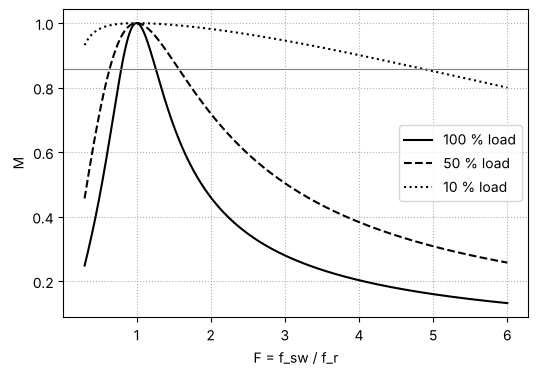

In [2]:
# Subtask 9.1.2 Frequency for 56 V input and gain curves
M_req = n * V_o / (56.0 / 2)
for load in (1.0, 0.1):
    F = optimize.brentq(lambda x: get_M_src(x, Q_full * load) - M_req, 1.0, 100)
    print(f"load {load*100:3.0f} %: M = {M_req:.3f} at F = {F:.3f}, f_sw = {F*f_r/1e6:.2f} MHz")

F = np.linspace(0.3, 6, 600)
plt.figure(figsize=(6, 4))
for load, ls in ((1.0, '-'), (0.5, '--'), (0.1, ':')):
    plt.plot(F, get_M_src(F, Q_full * load), 'k' + ls, label=f'{load*100:.0f} % load')
plt.axhline(M_req, color='gray', lw=0.8)
plt.xlabel('F = f_sw / f_r'); plt.ylabel('M'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 9.1.2 Solution

$f_\mathrm{r} = 1.00~\mathrm{MHz}$, $Z_0 = 10~\Omega$, $R_\mathrm{e} = 7.78~\Omega$, $Q = 1.29$; tank current $3.93~\mathrm{A}$, $C_\mathrm{r}$ peak $63.3~\mathrm{V}$. For $56~\mathrm{V}$ the gain must fall to $0.857$: $1.26~\mathrm{MHz}$ at full load, but $4.88~\mathrm{MHz}$ at $10~\%$ load. The SRC curves flatten at light load; without load no frequency regulates the output.


## 9.2 LLC converter with an input-voltage range

Full bridge, $n = 4$, $f_\mathrm{r} = 1~\mathrm{MHz}$, $12~\mathrm{V}$, $250~\mathrm{W}$, $V_\mathrm{in} = 40 \ldots 60~\mathrm{V}$, $M = nV_\mathrm{o}/V_\mathrm{in}$.

9.2.1 Create the functions
- `get_M_llc(F, Ln, Q)`: FHA gain of the LLC,
- `get_Zin(F, Ln, Q)`: input impedance of the tank normalised to $R_\mathrm{e}$,
- `get_peak(Ln, Q)`: peak gain and its frequency,
- `get_F_zvs(Ln, Q)`: highest frequency below $f_\mathrm{r}$ at which the input impedance turns capacitive.

Print the peak gains for $L_\mathrm{n} = 3, 5$ and $Q = 0.3 \ldots 0.6$ and the no-load gain limit $L_\mathrm{n}/(L_\mathrm{n}+1)$.

9.2.2 Design the tank for $L_\mathrm{n} = 3$, $Q = 0.5$: $L_\mathrm{r}$, $C_\mathrm{r}$, $L_\mathrm{m}$, the magnetising current and the primary rms current at $f_\mathrm{r}$. Find the frequency range ($M = 1.2$ at full load, $M = 0.8$ at $100~\%$, $50~\%$ and $10~\%$ load) and the ZVS limit. Plot the gain curves.


In [3]:
# Subtask 9.2.1 LLC functions and peak gains
def get_M_llc(F, Ln, Q):
    """FHA gain of the LLC."""
    return np.abs(Ln * F**2 / (((Ln + 1) * F**2 - 1) + 1j * (F**2 - 1) * F * Q * Ln))


def get_Zin(F, Ln, Q):
    """Input impedance of the tank normalised to R_e."""
    zm = 1j * Q * Ln * F
    return 1j * Q * (F - 1 / F) + zm / (1 + zm)


def get_peak(Ln, Q):
    """Peak gain between f0 and f_r and its normalised frequency."""
    F = np.linspace(1.0001 / np.sqrt(1 + Ln), 1.0, 20001)
    M = get_M_llc(F, Ln, Q)
    return M.max(), F[np.argmax(M)]


def get_F_zvs(Ln, Q):
    """Highest frequency below f_r at which the input impedance becomes capacitive."""
    F = np.linspace(1.0001 / np.sqrt(1 + Ln), 0.99999, 100001)
    k = np.where(np.diff(np.sign(np.imag(get_Zin(F, Ln, Q)))) != 0)[0]
    return F[k[-1]] if k.size else np.nan


for Ln in (3, 5):
    print(f"Ln = {Ln}: no-load gain limit {Ln/(Ln+1):.3f}; peak gain for Q = 0.3 ... 0.6: "
          + ", ".join(f"{get_peak(Ln, Q)[0]:.2f}" for Q in (0.3, 0.4, 0.5, 0.6)))


Ln = 3: no-load gain limit 0.750; peak gain for Q = 0.3 ... 0.6: 2.31, 1.79, 1.50, 1.32
Ln = 5: no-load gain limit 0.833; peak gain for Q = 0.3 ... 0.6: 1.75, 1.39, 1.20, 1.11


R_e = 7.47 Ohm, Z0 = 3.74 Ohm, L_r = 594 nH, C_r = 42.6 nF, L_m = 1.78 uH
I_m,pk = 6.73 A, primary rms 6.97 A (load part only 5.79 A)
peak gain 1.50 at F = 0.577; ZVS limit F = 0.619; M = 1.2 at F = 0.789
load 100 %: M = 0.8 at F = 1.485
load  50 %: M = 0.8 at F = 1.703
load  10 %: M = 0.8 at F = 1.975


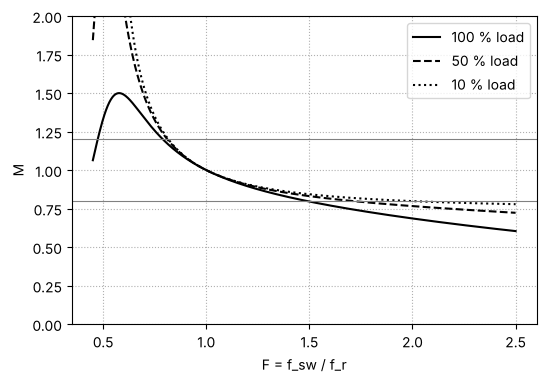

In [4]:
# Subtask 9.2.2 Tank design, frequency range and gain curves
n_l, V_o, P_o, f_r = 4, 12.0, 250.0, 1e6
Ln, Q = 3, 0.5
R_e = get_Re(n_l, V_o**2 / P_o)
Z0 = Q * R_e
L_r = Z0 / (2 * np.pi * f_r); C_r = 1 / (2 * np.pi * f_r * Z0); L_m = Ln * L_r
I_m = n_l * V_o / (4 * f_r * L_m)
i_load = np.pi * (P_o / V_o) / (2 * n_l)
print(f"R_e = {R_e:.2f} Ohm, Z0 = {Z0:.2f} Ohm, L_r = {L_r*1e9:.0f} nH, C_r = {C_r*1e9:.1f} nF, L_m = {L_m*1e6:.2f} uH")
print(f"I_m,pk = {I_m:.2f} A, primary rms {np.sqrt(i_load**2/2 + I_m**2/3):.2f} A (load part only {i_load/np.sqrt(2):.2f} A)")
pk, Fp = get_peak(Ln, Q)
F_low = optimize.brentq(lambda x: get_M_llc(x, Ln, Q) - 1.2, Fp, 1.0)
print(f"peak gain {pk:.2f} at F = {Fp:.3f}; ZVS limit F = {get_F_zvs(Ln, Q):.3f}; M = 1.2 at F = {F_low:.3f}")
for load in (1.0, 0.5, 0.1):
    F_high = optimize.brentq(lambda x: get_M_llc(x, Ln, Q * load) - 0.8, 1.0, 100)
    print(f"load {load*100:3.0f} %: M = 0.8 at F = {F_high:.3f}")

F = np.linspace(0.45, 2.5, 800)
plt.figure(figsize=(6, 4))
for load, ls in ((1.0, '-'), (0.5, '--'), (0.1, ':')):
    plt.plot(F, get_M_llc(F, Ln, Q * load), 'k' + ls, label=f'{load*100:.0f} % load')
for M in (0.8, 1.2):
    plt.axhline(M, color='gray', lw=0.8)
plt.ylim(0, 2); plt.xlabel('F = f_sw / f_r'); plt.ylabel('M'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 9.2.2 Solution

$L_\mathrm{n} = 5$ cannot reach $M = 0.8$ without load (limit $0.83$), $L_\mathrm{n} = 3$ can (limit $0.75$). With $Q = 0.5$: peak gain $1.50$, $Z_0 = 3.74~\Omega$, $L_\mathrm{r} = 594~\mathrm{nH}$, $C_\mathrm{r} = 42.6~\mathrm{nF}$, $L_\mathrm{m} = 1.78~\mu\mathrm{H}$. The magnetising current of $6.7~\mathrm{A}$ raises the primary rms current from $5.79$ to $6.97~\mathrm{A}$. FHA frequency range: $M = 1.2$ at $F = 0.79$, $M = 0.8$ at $F = 1.49$ (full load), $1.70$ ($50~\%$) and $1.97$ ($10~\%$); the ZVS limit $F = 0.62$ lies below the range.


## 9.3 DC transformer for brief B2

$48~\mathrm{V}$ to $12~\mathrm{V}$, $250~\mathrm{W}$, full bridge, $n = 4$, $f_\mathrm{sw} = f_\mathrm{r} = 1~\mathrm{MHz}$; primary: $Q_\mathrm{oss} = 10~\mathrm{nC}$, $R_\mathrm{DS(on)} = 7~\mathrm{m\Omega}$, $t_\mathrm{d} = 10~\mathrm{ns}$, $Q_\mathrm{TR} = 5~\mathrm{nC}$; SR: $R_\mathrm{DS(on)} = 1.5~\mathrm{m\Omega}$, $L_\mathrm{pkg} = 0.2~\mathrm{nH}$.

9.3.1 Calculate the upper bound of $L_\mathrm{m}$, the magnetising current for $L_\mathrm{m} = 4.7~\mu\mathrm{H}$, the primary rms current and the conduction loss of the primary bridge.

9.3.2 Plot the SR current $\hat{\imath}\sin\omega t$ and the sensed voltage $R_\mathrm{DS(on)}i + L_\mathrm{pkg}\,\mathrm{d}i/\mathrm{d}t$ over a half period, without compensation, with an $RC$ compensation ($\tau = L_\mathrm{pkg}/R_\mathrm{DS(on)}$) and with this compensation when $R_\mathrm{DS(on)}$ is $50~\%$ higher. Print the timing errors (phasor approximation) and the reverse-conduction loss without compensation ($V_\mathrm{SD} = 2~\mathrm{V}$).


In [5]:
# Subtask 9.3.1 Magnetising inductance and currents of the DCX
Q_oss, Q_TR, t_d, R_p = 10e-9, 5e-9, 10e-9, 7e-3
I_req = (2 * Q_oss + Q_TR) / t_d
L_m_max = n_l * V_o / (4 * f_r * I_req)
L_m = 4.7e-6
I_m = n_l * V_o / (4 * f_r * L_m)
I_rms = np.sqrt(i_load**2 / 2 + I_m**2 / 3)
print(f"required current {I_req:.2f} A, L_m <= {L_m_max*1e6:.2f} uH; with 4.7 uH: I_m,pk = {I_m:.2f} A")
print(f"primary rms {I_rms:.2f} A, conduction loss {2*I_rms**2*R_p:.2f} W "
      f"(without magnetising current {2*(i_load**2/2)*R_p:.2f} W)")


required current 2.50 A, L_m <= 4.80 uH; with 4.7 uH: I_m,pk = 2.55 A
primary rms 5.97 A, conduction loss 0.50 W (without magnetising current 0.47 W)


no compensation: zero crossing 40.0 deg (111 ns) early, reverse conduction 2.43 W per SR
compensation tau = 133 ns; with R_DS(on) 50 % higher: 10.8 deg (30 ns) late


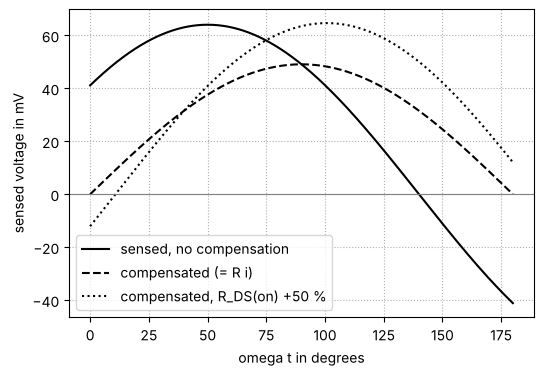

In [6]:
# Subtask 9.3.2 SR timing with and without compensation
R_sr, L_pkg, V_SD = 1.5e-3, 0.2e-9, 2.0
w = 2 * np.pi * f_r
i_hat = np.pi * (P_o / V_o) / 2
th = np.linspace(0, np.pi, 500)
i = i_hat * np.sin(th)
v_raw = R_sr * i + L_pkg * w * i_hat * np.cos(th)
err_raw = np.degrees(np.arctan(w * L_pkg / R_sr))
err_hot = np.degrees(np.arctan(w * L_pkg / (1.5 * R_sr)) - np.arctan(w * L_pkg / R_sr))
P_rev = V_SD * i_hat * (1 - np.cos(np.radians(err_raw))) / (2 * np.pi)
print(f"no compensation: zero crossing {err_raw:.1f} deg ({err_raw/360/f_r*1e9:.0f} ns) early, reverse conduction {P_rev:.2f} W per SR")
print(f"compensation tau = {L_pkg/R_sr*1e9:.0f} ns; with R_DS(on) 50 % higher: {abs(err_hot):.1f} deg ({abs(err_hot)/360/f_r*1e9:.0f} ns) late")

# phasor approximation of the filtered signals
v_comp = R_sr * i                                           # filter matched to R_sr
ph_hot = np.arctan(w * L_pkg / (1.5 * R_sr)) - np.arctan(w * L_pkg / R_sr)
v_hot = 1.5 * R_sr * i_hat * np.abs((1 + 1j * w * L_pkg / (1.5 * R_sr)) / (1 + 1j * w * L_pkg / R_sr)) * np.sin(th + ph_hot)
plt.figure(figsize=(6, 4))
plt.plot(np.degrees(th), v_raw * 1e3, 'k-', label='sensed, no compensation')
plt.plot(np.degrees(th), v_comp * 1e3, 'k--', label='compensated (= R i)')
plt.plot(np.degrees(th), v_hot * 1e3, 'k:', label='compensated, R_DS(on) +50 %')
plt.axhline(0, color='gray', lw=0.8)
plt.xlabel('omega t in degrees'); plt.ylabel('sensed voltage in mV'); plt.grid(True, ls=':'); plt.legend(); plt.show()


### 9.3.2 Solution

$I_\mathrm{m,pk} \geq 2.5~\mathrm{A}$, $L_\mathrm{m} \leq 4.8~\mu\mathrm{H}$; with $4.7~\mu\mathrm{H}$: $2.55~\mathrm{A}$, primary rms $5.97~\mathrm{A}$, conduction loss $0.50~\mathrm{W}$ (of which $0.03~\mathrm{W}$ due to the magnetising current). Without compensation the SR turns off $40^\circ$ ($111~\mathrm{ns}$) early and loses $2.4~\mathrm{W}$ per device in reverse conduction. The $RC$ compensation with $\tau = 133~\mathrm{ns}$ restores the zero crossing, but with $R_\mathrm{DS(on)}$ $50~\%$ higher the crossing comes $10.8^\circ$ ($30~\mathrm{ns}$) late and the SR conducts reverse current.


## 9.4 FHA versus time domain

Normalised model: full-bridge voltage $\pm 1$, $L_\mathrm{r} = 1$, $C_\mathrm{r} = 1$ ($\omega_\mathrm{r} = 1$, $Z_0 = 1$), $L_\mathrm{m} = L_\mathrm{n}$, ideal full-bridge rectifier into a constant voltage $M$ ($n = 1$). While the rectifier conducts, $L_\mathrm{m}$ sees $\pm M$; when the rectifier current $i_\mathrm{r} - i_\mathrm{m}$ is zero, $L_\mathrm{r}$ and $L_\mathrm{m}$ resonate in series with $C_\mathrm{r}$. For a load with quality factor $Q$ the average rectified current must equal $M/R_\mathrm{L} = 8QM/\pi^2$.

9.4.1 Create the function `get_I_rect(F, Ln, M_array)` that integrates the model for an array of output voltages at once (vectorised RK4) and returns the average rectified current, and the function `get_M_exact(F, Ln, Q)`. Compare the gain with FHA for the design of 9.2 at full load and $F = 0.65, 0.8, 1, 1.25, 1.5$.

9.4.2 Determine the frequency range of 9.2.2 with the time-domain model and compare it with FHA. (The vectorised model needs a few minutes for all points.)


In [7]:
# Subtask 9.4.1 Time-domain model (vectorised over the output voltage) and comparison with FHA
def get_I_rect(F, Ln, M, n_per=60, n_step=1200):
    """Average rectified current of the normalised LLC for an array of output voltages M."""
    M = np.asarray(M, float)
    x = np.zeros((M.size, 3))                        # i_r, v_c, i_m
    mode = np.zeros(M.size, int)                     # +1, -1: rectifier conducts; 0: off
    dt = 2 * np.pi / F / n_step

    def deriv(x, vs, mode):
        i_r, v_c = x[:, 0], x[:, 1]
        d_off = (vs - v_c) / (1 + Ln)
        on = mode != 0
        return np.stack([np.where(on, vs - v_c - M * mode, d_off), i_r,
                         np.where(on, M * mode / Ln, d_off)], axis=1)

    for p in range(n_per):
        acc = np.zeros(M.size)
        for k in range(n_step):
            vs = 1.0 if k < n_step // 2 else -1.0
            v_off = Ln * (vs - x[:, 1]) / (1 + Ln)    # voltage across L_m with the rectifier off
            off = mode == 0
            mode = np.where(off & (v_off >= M), 1, np.where(off & (v_off <= -M), -1, mode))
            k1 = deriv(x, vs, mode); k2 = deriv(x + 0.5 * dt * k1, vs, mode)
            k3 = deriv(x + 0.5 * dt * k2, vs, mode); k4 = deriv(x + dt * k3, vs, mode)
            xn = x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
            i_s = xn[:, 0] - xn[:, 2]
            v_off = Ln * (vs - xn[:, 1]) / (1 + Ln)
            end_p = (mode == 1) & (i_s <= 0); end_n = (mode == -1) & (i_s >= 0)
            xn[end_p | end_n, 2] = xn[end_p | end_n, 0]
            mode = np.where(end_p, np.where(v_off <= -M, -1, 0), mode)
            mode = np.where(end_n, np.where(v_off >= M, 1, 0), mode)
            acc += 0.5 * (np.abs(x[:, 0] - x[:, 2]) + np.abs(xn[:, 0] - xn[:, 2]))
            x = xn
    return acc / n_step


def get_M_exact(F, Ln, Q):
    """Gain for which the rectified current equals the load current 8 Q M / pi^2 (two grid passes)."""
    M_f = get_M_llc(F, Ln, Q)
    grid = np.linspace(0.6 * M_f, 1.6 * M_f, 15)
    for _ in range(2):
        g = get_I_rect(F, Ln, grid) - 8 * Q * grid / np.pi**2
        k = np.where(np.diff(np.sign(g)) != 0)[0][0]
        M = grid[k] - g[k] * (grid[k + 1] - grid[k]) / (g[k + 1] - g[k])
        grid = np.linspace(grid[k], grid[k + 1], 9)
    return M


print("   F    FHA   time domain")
for F in (0.65, 0.8, 1.0, 1.25, 1.5):
    print(f"{F:5.2f}  {get_M_llc(F, Ln, Q):.3f}  {get_M_exact(F, Ln, Q):.3f}")


   F    FHA   time domain

 0.65  1.423  1.787


 0.80  1.186  1.262


 1.00  1.000  1.002


 1.25  0.875  0.832


 1.50  0.796  0.727


In [8]:
# Subtask 9.4.2 Frequency range with the time-domain model
def find_F(Q_load, M_target, F_a, F_b, n=5):
    """Frequency at which the time-domain gain equals M_target (coarse sweep, then a finer sweep)."""
    for _ in range(2):
        Fs = np.linspace(F_a, F_b, n)
        Ms = np.array([get_M_exact(F, Ln, Q_load) for F in Fs])
        k = np.where(np.diff(np.sign(Ms - M_target)) != 0)[0][0]
        F_a, F_b = Fs[k], Fs[k + 1]
    return F_a + (M_target - Ms[k]) * (F_b - F_a) / (Ms[k + 1] - Ms[k])


F_12 = find_F(Q, 1.2, 0.78, 0.9)
F_08 = find_F(Q, 0.8, 1.1, 1.5)
F_08_10 = find_F(0.1 * Q, 0.8, 1.2, 2.0)
print(f"time domain: M = 1.2 at F = {F_12:.3f}; M = 0.8 at F = {F_08:.3f} (full load), {F_08_10:.3f} (10 % load)")


time domain: M = 1.2 at F = 0.833; M = 0.8 at F = 1.314 (full load), 1.693 (10 % load)


### 9.4.2 Solution

FHA is exact at $f_\mathrm{r}$, underestimates the gain below resonance (at $F = 0.65$ by $26~\%$) and overestimates it above (at $F = 1.5$ by $9~\%$). With the time-domain model $M = 1.2$ is reached at $F = 0.83$ (FHA $0.79$) and $M = 0.8$ at $F = 1.31$ (FHA $1.49$) at full load and at $F = 1.69$ (FHA $1.97$) at $10~\%$ load: the real frequency range is narrower. FHA is a safe starting point for the gain at low line, but the frequency limits, the currents and ZVS are taken from the time-domain model.
